# Retail Product Recommendation using LightGCN - walkthrough
End-to-end run on Amazon Reviews 2023 (Video_Games, subsample). Run `python -m src.data`, `python -m src.train`, `python -m src.evaluate` first; this notebook loads the saved checkpoints so numbers match `results/metrics.csv`.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, matplotlib.pyplot as plt
from src import config as C, graph as G
from src.evaluate import evaluate
from src.train import load_trained
pd.set_option('display.max_colwidth', 70); pd.set_option('display.width', 200)

## 1. Data
Temporal split (train < valid < test), positives = rating >= 4.

In [2]:
tr, va, te = (G.load_split(s) for s in ('train','val','test'))
items = pd.read_csv(C.PROC_DIR/'items.csv')
print({n: len(d) for n, d in zip(('train','val','test'), (tr, va, te))})
print('time ranges (ms):', [(int(d.timestamp.min()), int(d.timestamp.max())) for d in (tr, va, te)])
items.head()

{'train': 147013, 'val': 5640, 'test': 2912}
time ranges (ms): [(946850956000, 1628643000624), (1628644724721, 1657982696957), (1658004566446, 1688681657272)]


,item,asin,title,category,price
0,0,0375869026,Wonder,PC > Games,9.40
1,1,0399588175,Born a Crime: Stories from a South African Childhood,PC > Games,14.63
2,2,0744018706,Playing With Super Power: Nintendo Super NES Classics,Legacy Systems > Nintendo Systems,43.98
3,3,1524101036,Art of Atari,Legacy Systems > Atari Systems,NaN
4,4,1616611898,Descent: Journeys in the Dark 2nd Edition,PC > Games,NaN


## 2. Graph (training edges only)

{'users': 22269, 'items': 7811, 'edges': 147013, 'density': 0.0008451783953170587, 'avg_user_degree': 6.601688445821545, 'avg_item_degree': 18.821277685315582}
normalised adjacency (30080, 30080) nnz 294026


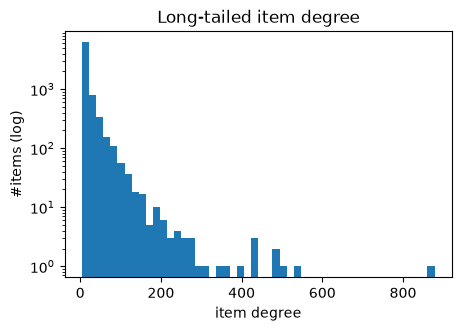

In [3]:
nu, ni = G.sizes()
print(G.graph_stats(tr.user.values, tr.item.values, nu, ni))
A = G.build_norm_adj(tr.user.values, tr.item.values, nu, ni)
print('normalised adjacency', tuple(A.shape), 'nnz', A._nnz())
deg = tr.item.value_counts()
plt.figure(figsize=(5,3.2)); plt.hist(deg, bins=50, log=True); plt.xlabel('item degree'); plt.ylabel('#items (log)'); plt.title('Long-tailed item degree'); plt.show()

## 3. Training curves (from the saved training run)

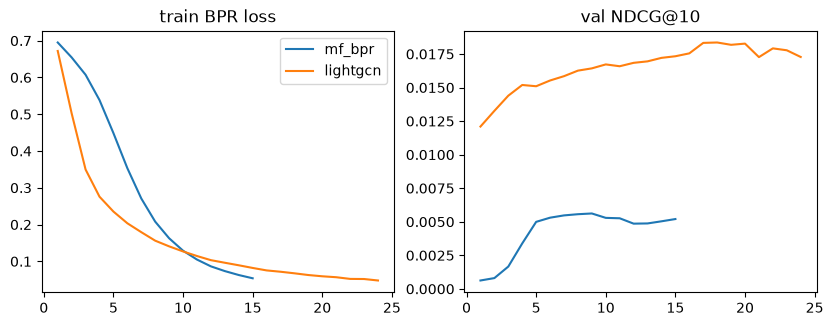

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for n in ('mf_bpr', 'lightgcn'):
    h = pd.read_csv(C.RESULTS_DIR/f'history_{n}.csv')
    ax[0].plot(h.epoch, h.train_bpr_loss, label=n); ax[1].plot(h.epoch, h['val_ndcg@10'], label=n)
ax[0].set_title('train BPR loss'); ax[1].set_title('val NDCG@10'); ax[0].legend(); plt.show()

## 4. Test evaluation (full ranking, train+val history masked)

In [5]:
rows = []
for n in ('popularity', 'mf_bpr', 'lightgcn'):
    m = load_trained(n, tr, nu, ni)
    rows.append({'model': n, **evaluate(m, te, [tr, va], ni)})
res = pd.DataFrame(rows).set_index('model'); res.round(4)

,precision@5,recall@5,ndcg@5,precision@10,recall@10,ndcg@10,precision@20,recall@20,ndcg@20,n_eval_users
model,,,,,,,,,,
popularity,0.0035,0.0120,0.0078,0.0033,0.0224,0.0113,0.0030,0.0384,0.0157,2111
mf_bpr,0.0012,0.0036,0.0026,0.0014,0.0083,0.0042,0.0012,0.0146,0.0060,2111
lightgcn,0.0056,0.0173,0.0125,0.0046,0.0296,0.0167,0.0037,0.0478,0.0217,2111


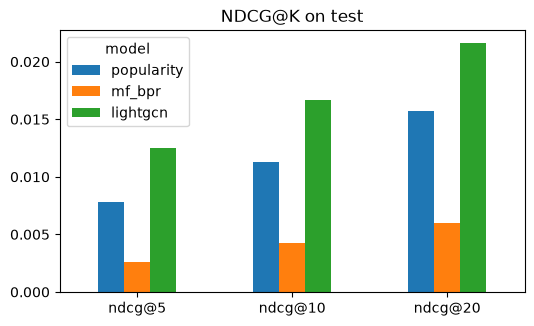

In [6]:
res[[f'ndcg@{k}' for k in C.KS]].T.plot.bar(figsize=(6, 3.4), rot=0, title='NDCG@K on test'); plt.show()

## 5. Recommendations

In [7]:
from src.recommend import Recommender
rec = Recommender()
uid = rec.users.user_id[0]
print('Past purchases:'); display(rec.history(uid).head(6))
print('Top-10 recommendations:'); display(rec.recommend(uid, 10))

Past purchases:


,asin,title,category,price
0,B07QX99XJJ,Corsair HS35 - Stereo Gaming Headset - Memory Foam Earcups - Works...,PC > Accessories > Headsets,41.99
1,B01GY35T4S,Xbox One S 1TB Console - NBA 2K20 Bundle - [DISCONTINUED],Xbox One > Consoles,275.00
2,B07SNN8GV5,Call of Duty: Modern Warfare Battle Pass Edition - [Xbox One Digit...,Xbox One > Games,NaN
3,B082R1RGZF,Turtle Beach Stealth 300 Amplified Surround Sound Gaming Headset f...,Xbox One > Accessories > Headsets,NaN


Top-10 recommendations:


,rank,asin,title,category,price,score
0,1,B01N3ASPNV,amFilm Tempered Glass Screen Protector for Nintendo Switch 2017 (2...,"Nintendo Switch > Accessories > Faceplates, Protectors & Skins > S...",8.91,6.288943
1,2,B077GG9D5D,DualShock 4 Wireless Controller for PlayStation 4 - Jet Black,PlayStation 4 > Accessories > Controllers > Gamepads & Standard Co...,57.00,6.195684
2,3,B0BYVN9ZK2,Razer Kraken Gaming Headset: Lightweight Aluminum Frame - Retracta...,PC > Accessories > Headsets,44.95,5.978602
3,4,B089QYP649,Turtle Beach Stealth 600 Wireless Surround Sound Gaming Headset fo...,PlayStation 4 > Accessories > Headsets,168.75,5.877608
4,5,B094YHB1QK,PlayStation DualSense Wireless Controller – Galactic Purple,PlayStation 5 > Accessories > Controllers,74.99,5.529834
5,6,B0C5K4M7WJ,"HyperX Cloud II Wireless - Gaming Headset for PC, PS4/PS5, Nintend...",PC > Accessories > Headsets,119.99,5.387463
6,7,B0883P3VSH,"Turtle Beach Recon 50 Xbox Gaming Headset for Xbox Series X/ S, Xb...",Legacy Systems > PlayStation Systems > PlayStation > Accessories,24.95,5.259244
7,8,B072C3VM5F,Far Cry 5 Gold Edition - Xbox One [Digital Code],Xbox One > Games,NaN,4.941797
8,9,B0BN5DC36N,Seagate Horizon Forbidden West Limited Edition Game Drive for Play...,Legacy Systems > PlayStation Systems > PlayStation > Accessories,89.99,4.813971
9,10,B004RMK5QG,PlayStation Plus: 12 Month Membership [Digital Code],Online Game Services > PlayStation Network > Subscriptions,NaN,4.751731


## 6. Cold start - profile from picked products

In [8]:
picked = items[items.title.str.contains('Zelda: Breath of the Wild', case=False)].asin.head(2).tolist()
print(picked); display(rec.recommend_from_profile(picked, 10))

['B01N10NIBP', 'B06WLK5CHQ']


,rank,asin,title,category,price,score
0,1,B01N3ASPNV,amFilm Tempered Glass Screen Protector for Nintendo Switch 2017 (2...,"Nintendo Switch > Accessories > Faceplates, Protectors & Skins > S...",8.91,13.870553
1,2,B087NNPYP3,The Legend of Zelda: Breath of the Wild Master Edition - Nintendo ...,Nintendo Switch > Consoles,NaN,10.279547
2,3,B07624RBWB,Nintendo Switch Pro Controller,Nintendo Switch > Accessories > Controllers,69.00,10.077675
3,4,B011ALF4XK,Luigi amiibo (Super Mario Bros Series),Legacy Systems > Nintendo Systems > Wii U > Interactive Gaming Fig...,NaN,8.083031
4,5,B087SHFL9B,Super Mario Odyssey - Nintendo Switch,Nintendo Switch > Games,53.98,8.064924
5,6,B08D3XL1KF,Super Smash Bros. Ultimate: Challenger Pack 2 - [Switch Digital Code],Nintendo Switch > Games,5.99,7.884775
6,7,B01N4NTNO2,Nintendo amiibo-Link (Archer): Breath of the Wild,Legacy Systems > Nintendo Systems > Wii U > Accessories,43.99,7.786118
7,8,B08L6L6KQL,HORI Compact Playstand for Nintendo Switch Officially Licensed by ...,"Nintendo Switch > Accessories > Mounts, Brackets & Stands",22.33,7.752508
8,9,B01N6QPWBV,Nintendo amiibo-Guardian: Breath of the Wild,Legacy Systems > Nintendo Systems > Wii U > Accessories,43.79,7.751414
9,10,B071Y79VNL,Nintendo amiibo - Corrin (Player 2) (SSB),Nintendo Switch > Accessories,28.40,7.750982
